# 11 · EdNet-KT1: exploratory data analysis

Supports thesis Section 4.2 (*Exploratory analysis*). The main cohort is the 5,000-learner one (the cohort size pyKT's own EdNet setup samples); the split check runs on every cohort.

The questions it answers, and why they matter for the models:
* How long are learners' sequences and how skewed are items and KCs? (cold start; long tail of KCs)
* How do correctness and response time differ by TOEIC part? (KC dimension used in the learner model)
* Does correctness change along a learner's sequence? (the signal KT models exploit)
* How are learner-level quantities related? (Spearman correlations)
* How much of the test fold is new to the training fold? (item-id models such as AKT and SAINT)

**Where to run.** Locally (recommended): `.venv-kt` with `requirements-analysis.txt`, started from the repository; no GPU needed.
**On Colab (CPU runtime is enough):** upload `ednet_colab_bundle.zip` (built by `knowledge_tracing/make_colab_bundle.py`) to `MyDrive/ednet_kt1/`; the training runs already live in `MyDrive/ednet_kt1/data/benchmarks/` (for the English run, upload `data/benchmarks/english_kt/` there too). Then *Runtime → Run all*: the first cell mounts Drive, unpacks the bundle and links the benchmark folder. Figures and tables are written to `data/benchmarks/report/` (on Drive when on Colab).

In [1]:
import sys, os
if "google.colab" in sys.modules:
    !pip install -q seaborn
from pathlib import Path
_root = Path.cwd().resolve()
while not (_root / "knowledge_tracing").is_dir() and _root.parent != _root:
    _root = _root.parent
if "google.colab" in sys.modules and not (_root / "knowledge_tracing").is_dir():
    import zipfile
    from google.colab import drive
    drive.mount("/content/drive")
    import time as _t
    with zipfile.ZipFile("/content/drive/MyDrive/ednet_kt1/ednet_colab_bundle.zip") as zf:
        for _i in zf.infolist():   # keep the zip's timestamps: the runner compares mtimes
            _p = zf.extract(_i, "/content/ednet")
            _m = _t.mktime(_i.date_time + (0, 0, -1))
            os.utime(_p, (_m, _m))
    _root = Path("/content/ednet")
sys.path[:0] = [str(_root), str(_root / "knowledge_tracing")]
import report_utils as ru
ROOT = ru.setup()
ru.style()
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
pd.set_option("display.width", 160, "display.max_columns", 30)
print("repository:", ROOT)

repository: /home/rene/MicroLearningThesis


In [2]:
import eda
COHORT = 5000
EDNET = Path("data/external/ednet")
a = eda.answers_only(pd.read_csv(EDNET / f"kt1_events_{COHORT}.csv"))
ov = eda.overview(a)
display(pd.Series(ov).to_frame("value"))

,value
learners,5000.0000
answers,452335.0000
items,11423.0000
KCs,143.0000
dimensions,7.0000
correct rate,0.6026
mean answers per learner,90.4700
median answers per learner,51.0000


## 1. Descriptive statistics

In [3]:
desc = eda.describe_table(a)
display(desc.round(3))
ru.save_table(desc, "ednet_describe", f"Descriptive statistics, EdNet-KT1 cohort of {COHORT:,} learners",
              "tab:ednet-describe", digits=2, align="lrrrrrrrr", size="footnotesize")

,quantity,n,mean,sd,min,Q1,median,Q3,max
0,Answers per learner,5000.0,90.467,70.927,20.000,30.000,51.000,179.250,200.0
1,Accuracy per learner,5000.0,0.546,0.163,0.000,0.433,0.570,0.667,1.0
2,Answers per item,11423.0,39.599,141.742,1.000,6.000,16.000,33.000,2938.0
3,Accuracy per item,11423.0,0.665,0.243,0.000,0.500,0.688,0.846,1.0
4,Answers per KC,143.0,3163.182,3581.308,3.000,1612.000,2176.000,3252.500,21995.0
5,Accuracy per KC,143.0,0.627,0.121,0.156,0.562,0.629,0.691,1.0
6,Response time (s),452335.0,25.306,30.173,0.000,16.000,21.000,29.000,4949.0


table  -> data/benchmarks/report/tables/ednet_describe.tex


## 2. Distributions

figure -> data/benchmarks/report/figures/ednet_distributions.png


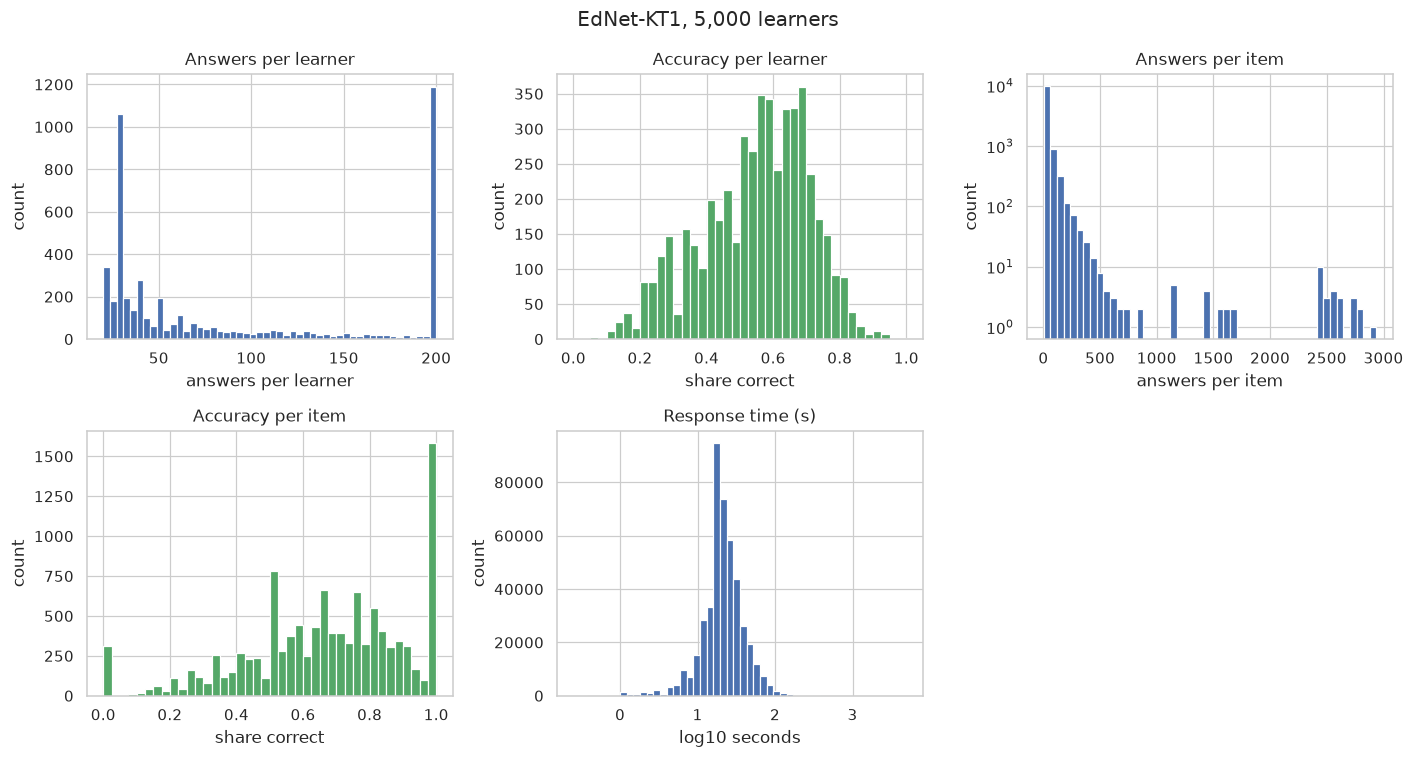

In [4]:
fig = eda.plot_distributions(a, f"EdNet-KT1, {COHORT:,} learners")
ru.save_fig(fig, "ednet_distributions"); plt.show()

figure -> data/benchmarks/report/figures/ednet_kc_longtail.png


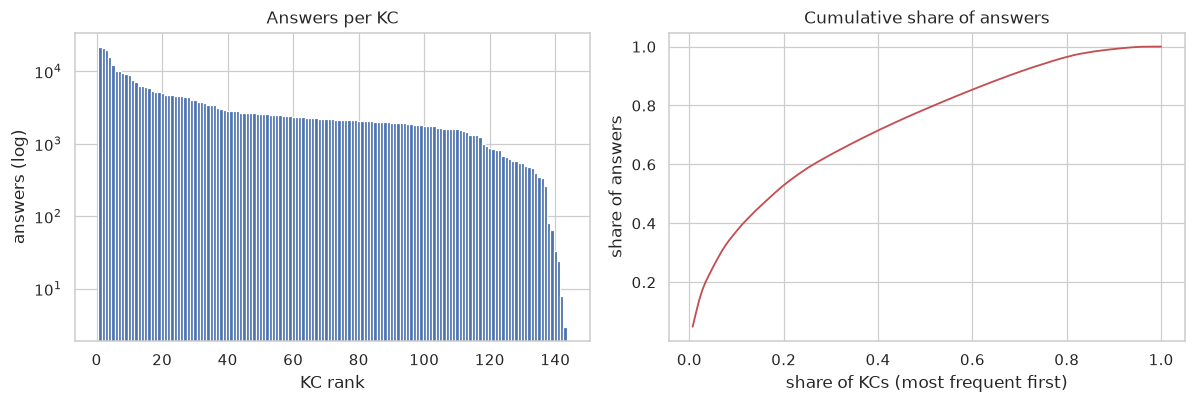

the 10% most frequent KCs carry 38.3% of the answers


In [5]:
fig, top10 = eda.kc_longtail(a)
ru.save_fig(fig, "ednet_kc_longtail"); plt.show()
print(f"the 10% most frequent KCs carry {top10:.1%} of the answers")

## 3. TOEIC part (KC dimension)

,TOEIC part,answers,items,KCs,correct rate,median response time (s)
0,part1,48261,641,20,0.6925,22.0
1,part2,87176,1400,17,0.6856,17.0
2,part3,19606,1006,7,0.6000,25.3
3,part4,33538,990,14,0.4572,23.0
4,part5,215575,5754,71,0.5694,21.2
5,part6,30234,644,5,0.6565,26.3
6,part7,17945,988,9,0.5398,54.0


table  -> data/benchmarks/report/tables/ednet_by_part.tex


figure -> data/benchmarks/report/figures/ednet_by_part.png


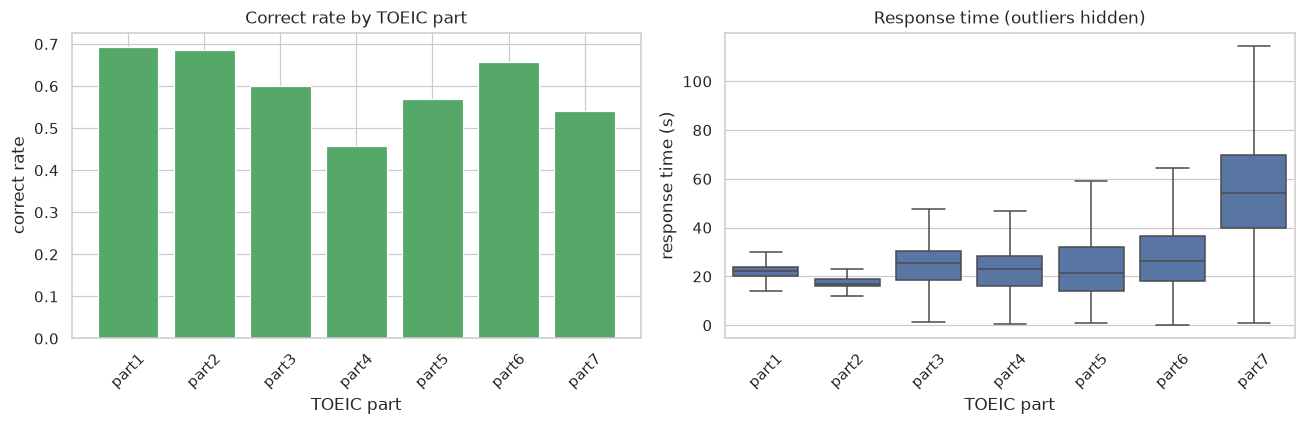

In [6]:
dim = eda.by_dimension(a).rename(columns={"kc_dimension": "TOEIC part"})
display(dim)
ru.save_table(dim, "ednet_by_part", "EdNet-KT1 answers by TOEIC part (5,000 cohort)", "tab:ednet-by-part", digits=3)
fig = eda.plot_by_dimension(a, "TOEIC part"); ru.save_fig(fig, "ednet_by_part"); plt.show()

## 4. Correctness along the sequence
The shaded bars show how many learners reach each position: later positions are answered only by the learners who stayed, so the curve mixes learning with selection (longer-staying learners are stronger).

figure -> data/benchmarks/report/figures/ednet_accuracy_by_position.png


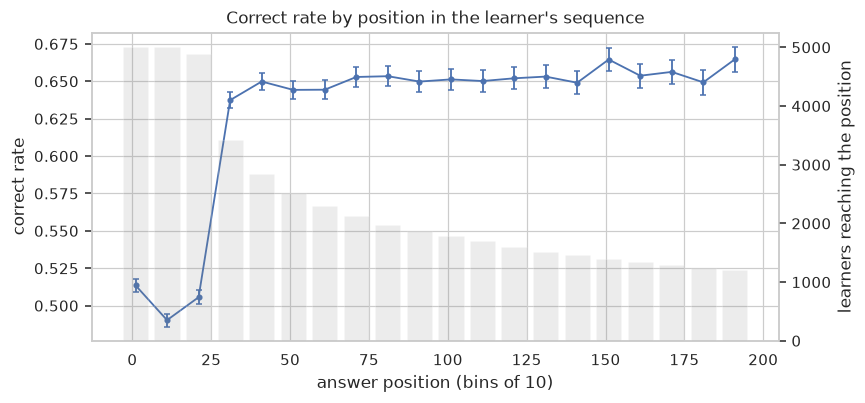

,bin,mean,count,ci,learners
0,1,0.5135,50000,0.0044,5000
1,11,0.4903,50000,0.0044,5000
4,41,0.6498,27294,0.0057,2844
9,91,0.6498,18234,0.0069,1864
14,141,0.6490,14248,0.0078,1452
19,191,0.6647,11935,0.0085,1206


In [7]:
fig, pos = eda.accuracy_by_position(a)
ru.save_fig(fig, "ednet_accuracy_by_position"); plt.show()
display(pos.iloc[[0, 1, 4, 9, 14, 19]].round(4))

### The first 30 answers
The position curve steps up after answer 30 and many learners stop at exactly 30 answers. The checks below describe that block: how concentrated its items are and how its TOEIC-part mix differs. The pattern is consistent with a common initial placement block; the data alone cannot say how the app assigned it.

In [8]:
lens = a.groupby("learner_id").size()
first, later = a[a["position"] <= 30], a[a["position"] > 30]
top100 = first["item_id"].value_counts().head(100).sum() / len(first)
block = pd.DataFrame([
    ["learners with exactly 30 answers", int((lens == 30).sum())],
    ["learners with exactly 29 / 31 answers", f"{int((lens == 29).sum())} / {int((lens == 31).sum())}"],
    ["share of answers 1-30 on the 100 most common items", round(float(top100), 3)],
    ["learners whose first item is the most common first item", int(a[a["position"] == 1]["item_id"].value_counts().iloc[0])],
    ["correct rate, answer 30 / answer 31", f"{first[first['position'] == 30]['correct'].mean():.3f} / {later[later['position'] == 31]['correct'].mean():.3f}"],
    ["correct rate, answers 1-30 / 31+", f"{first['correct'].mean():.3f} / {later['correct'].mean():.3f}"],
], columns=["check", "value"])
display(block)
mix = pd.concat([first["kc_dimension"].value_counts(normalize=True).rename("answers 1-30"),
                 later["kc_dimension"].value_counts(normalize=True).rename("answers 31+")], axis=1).round(3)
mix = mix.sort_index().reset_index(names="TOEIC part")
display(mix)
ru.save_table(block, "ednet_first_block", "The first 30 answers of each learner (5,000 cohort)", "tab:ednet-first-block", digits=3, align="lr")
ru.save_table(mix, "ednet_first_block_parts", "TOEIC-part mix of answers 1-30 and later answers", "tab:ednet-first-block-parts", digits=3)

,check,value
0,learners with exactly 30 answers,974
1,learners with exactly 29 / 31 answers,38 / 63
2,share of answers 1-30 on the 100 most common i...,0.58
3,learners whose first item is the most common f...,2363
4,"correct rate, answer 30 / answer 31",0.445 / 0.630
5,"correct rate, answers 1-30 / 31+",0.503 / 0.650


,TOEIC part,answers 1-30,answers 31+
0,part1,0.130,0.095
1,part2,0.133,0.221
2,part3,0.036,0.047
3,part4,0.148,0.039
4,part5,0.439,0.495
5,part6,0.050,0.075
6,part7,0.065,0.028


table  -> data/benchmarks/report/tables/ednet_first_block.tex
table  -> data/benchmarks/report/tables/ednet_first_block_parts.tex


## 5. Learner-level correlations (Spearman)

figure -> data/benchmarks/report/figures/ednet_learner_correlation.png


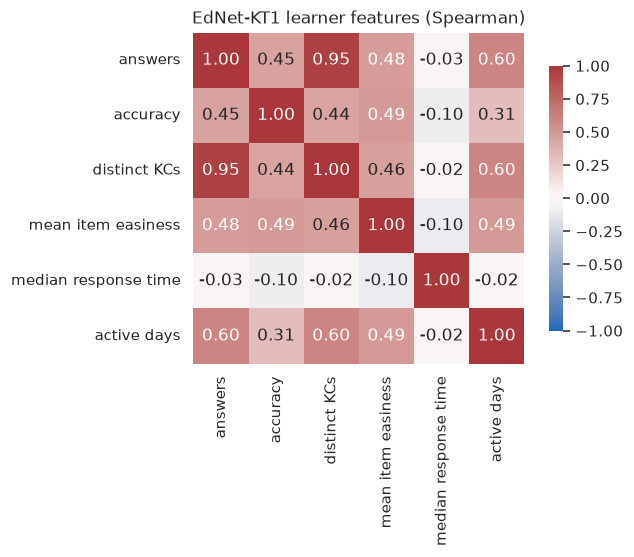

In [9]:
feat = eda.learner_features(a)
fig, corr = eda.plot_correlation(feat, "EdNet-KT1 learner features (Spearman)")
ru.save_fig(fig, "ednet_learner_correlation"); plt.show()

## 6. Split check on every cohort
No learner may appear in two folds. The share of test answers on items never answered in the training fold matters for models with an embedding per item (AKT, SAINT): such items keep an untrained embedding.

In [10]:
BENCH = ru.ednet_bench_dir()
rows = []
for n in [300, 1000, 2000, 5000, 10000, 20000]:
    sp_path = BENCH / f"ednet_kt1_{n}/kt/processed/split_assignments.csv"
    if not sp_path.exists():
        continue
    an = a if n == COHORT else eda.answers_only(pd.read_csv(EDNET / f"kt1_events_{n}.csv"))
    rows.append({"learners": n, **eda.split_coverage(an, pd.read_csv(sp_path))})
cov = pd.DataFrame(rows)
display(cov)
assert (cov["learners in more than one split"] == 0).all()
ru.save_table(cov[["learners", "test answers", "test answers on items unseen in train", "test items unseen in train"]],
              "ednet_unseen_items", "Test answers on items not seen in the training fold", "tab:ednet-unseen", digits=4)

,learners,train learners,valid learners,test learners,learners in more than one split,test answers,test answers on items unseen in train,test items unseen in train,test answers on KCs unseen in train
0,300,210,30,60,0,6046,0.1793,0.3029,0.0000
1,1000,700,100,200,0,19687,0.0424,0.1053,0.0000
2,2000,1400,200,400,0,36017,0.0164,0.0581,0.0001
3,5000,3500,500,1000,0,89679,0.0034,0.0224,0.0000
4,10000,7000,1000,2000,0,182813,0.0011,0.0126,0.0000
5,20000,14000,2000,4000,0,368480,0.0003,0.0065,0.0000


table  -> data/benchmarks/report/tables/ednet_unseen_items.tex


In [11]:
print("Summary for the thesis text (5,000 cohort):")
lens = a.groupby("learner_id").size()
print(f"- {ov['learners']:,} learners, {ov['answers']:,} answers, {ov['items']:,} items, {ov['KCs']} KCs; correct rate {ov['correct rate']:.3f}")
print(f"- answers per learner: median {lens.median():.0f}, {(lens >= 200).mean():.1%} truncated at 200")
print(f"- 10% most frequent KCs: {top10:.1%} of answers")
print(f"- correct rate by part: {dim['correct rate'].min():.3f}-{dim['correct rate'].max():.3f}")
print(f"- correct rate, answers 1-30 vs 31+: {first['correct'].mean():.3f} vs {later['correct'].mean():.3f}; {(lens == 30).sum()} learners stop at exactly 30")

Summary for the thesis text (5,000 cohort):
- 5,000 learners, 452,335 answers, 11,423 items, 143 KCs; correct rate 0.603
- answers per learner: median 51, 23.6% truncated at 200
- 10% most frequent KCs: 38.3% of answers
- correct rate by part: 0.457-0.693
- correct rate, answers 1-30 vs 31+: 0.503 vs 0.650; 974 learners stop at exactly 30
